Loaded 50 epochs


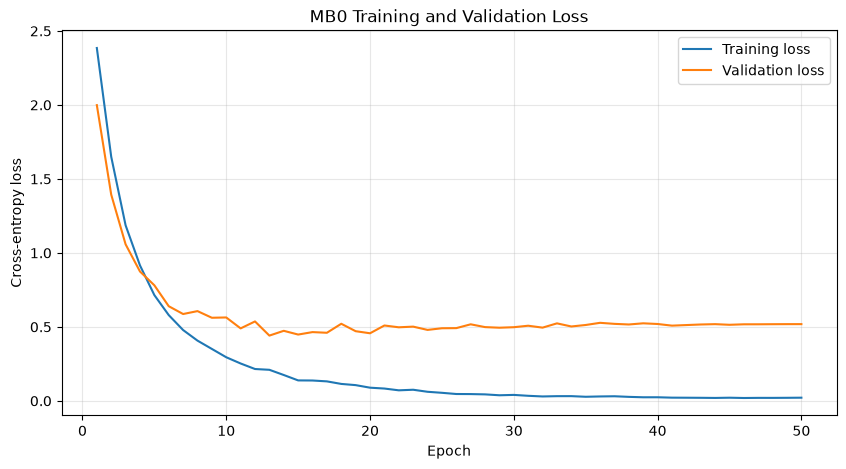

In [7]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Locate the training results
metrics_path = Path(
    "/home/jb5dk/ds6050/ds6050-final-project/outputs/mb0-my-seed42/metrics.jsonl"
)

# Read epoch-by-epoch metrics
records = []

with metrics_path.open() as file:
    for line in file:
        records.append(json.loads(line))

print(f"Loaded {len(records)} epochs")

# Convert to a DataFrame
df = pd.json_normalize(records)

# Plot training and validation loss
plt.figure(figsize=(10, 5))
plt.plot(df["epoch"], df["train.loss"], label="Training loss")
plt.plot(df["epoch"], df["val.loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("MB0 Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [8]:
rows = []

for record in records:
    rows.append({
        "epoch": record["epoch"],
        "train_loss": record["train"]["loss"],
        "val_loss": record["val"]["loss"],
        "train_f1": record["train"]["macro_f1"],
        "val_f1": record["val"]["macro_f1"],
        "train_accuracy": record["train"]["accuracy"],
        "val_accuracy": record["val"]["accuracy"]
    })

df = pd.DataFrame(rows)

df.head()

,epoch,train_loss,val_loss,train_f1,val_f1,train_accuracy,val_accuracy
0,1,2.384943,1.998773,0.078304,0.162712,0.184263,0.256917
1,2,1.649872,1.393854,0.358135,0.421052,0.423307,0.521739
2,3,1.186524,1.058024,0.529992,0.598813,0.579681,0.667984
3,4,0.915446,0.874341,0.659792,0.658145,0.679283,0.719368
4,5,0.714794,0.781049,0.743390,0.713630,0.752988,0.754941


In [9]:
best_idx = df["val_f1"].idxmax()
best_epoch = int(df.loc[best_idx, "epoch"])

print("Best epoch:", best_epoch)
print("Best validation macro-F1:", df.loc[best_idx, "val_f1"])
print("Validation accuracy:", df.loc[best_idx, "val_accuracy"])

Best epoch: 24
Best validation macro-F1: 0.9184650475579346
Validation accuracy: 0.9169960474308301


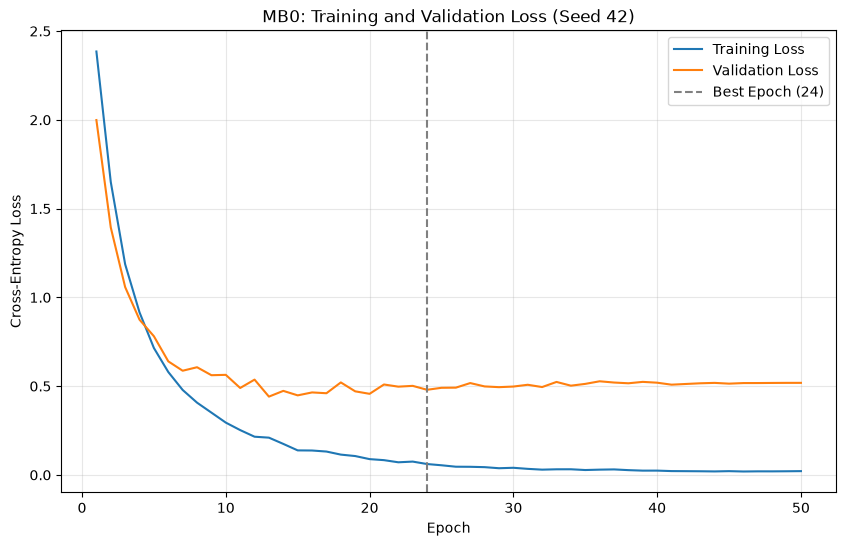

In [12]:
plt.figure(figsize=(10, 6))
plt.plot(df["epoch"], df["train_loss"], label="Training Loss")
plt.plot(df["epoch"], df["val_loss"], label="Validation Loss")
plt.axvline(
    best_epoch,
    linestyle="--",
    color="gray",
    label=f"Best Epoch ({best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("MB0: Training and Validation Loss (Seed 42)")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    metrics_path.parent / "loss_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

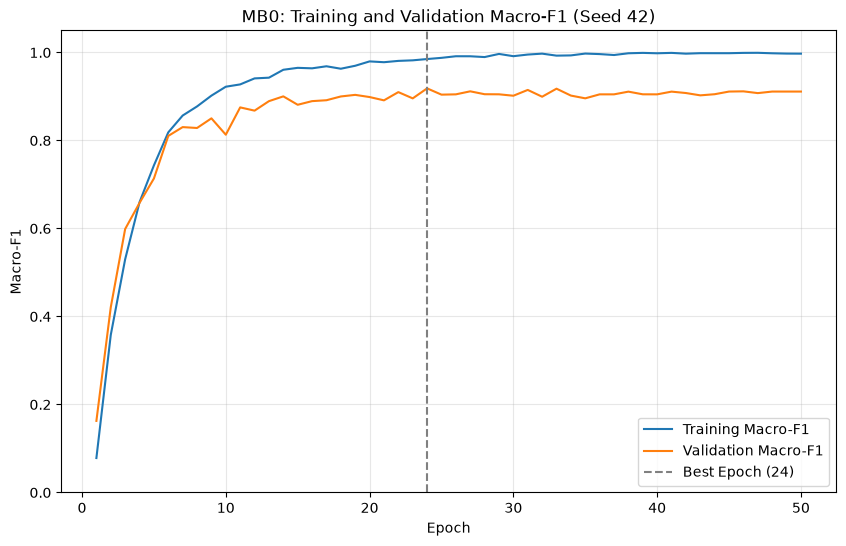

In [13]:
plt.figure(figsize=(10, 6))

plt.plot(df["epoch"], df["train_f1"], label="Training Macro-F1")
plt.plot(df["epoch"], df["val_f1"], label="Validation Macro-F1")

plt.axvline(
    best_epoch,
    linestyle="--",
    color="gray",
    label=f"Best Epoch ({best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("MB0: Training and Validation Macro-F1 (Seed 42)")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    metrics_path.parent / "f1_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()